In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload
from scipy.stats import spearmanr
import re
import arviz as az
import pymc as pm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import scipy.stats
import cellbayesassay as cba
from matplotlib.gridspec import GridSpec
import pickle
import itertools
import os.path
import os
import string
import attila_utils
plt.rcParams['figure.dpi'] = 200

In [2]:
my_treatments = ['TI21', 'TI22', 'TI26']
treatment2drugname = dict(zip(my_treatments, ['TUDCA', 'Cysteamine', 'Arundine']))
#treatment2drugname = dict(zip(my_treatments, ['Chenodiol', 'Cysteamine', 'Arundine']))

concentrations = {
    ('TI21', 1): 100e-6,
    ('TI21', 2): 10e-6,
    ('TI21', 3): 1e-6,
    ('TI22', 1): 10e-6,
    ('TI22', 2): 3e-6,
    ('TI22', 3): 1e-6,
    ('TI26', 1): 10e-6,
    ('TI26', 2): 3e-6,
    ('TI26', 3): 1e-6,
}



def get_concentration(TI, conc, concentrations=concentrations):
    TI = TI.strip()
    if re.match('^TI.*', TI):
        val = concentrations[(TI, conc)]
    else:
        val = concentrations[TI]
    return(val)

fpath = '../../resources/cell-based-assays/TI21_22_26_rawdata_sum-edited.xlsx'
datad = {}

def read_data(sheet_name, assays, mean_sem_col='Group', skiprows=0):
    data = pd.read_excel(fpath, sheet_name=sheet_name, skiprows=skiprows)
    data = data.loc[~ data[mean_sem_col].isin(['mean', 'SEM'])]
    data['TI'] = data.TI.apply(lambda s: re.sub('TI\\s+', 'TI', s)).str.strip()
    data = data.applymap(lambda x: 0 if x == '<LOD' else x)
    data = data.applymap(lambda x: pd.NA if x == 'N/A' else x)
    data_nonassays = data.loc[:, ~ data.columns.isin(assays)]
    data_assays = pd.concat([data[a].astype(np.float64).to_frame(a) for a in assays], axis=1)
    data = pd.concat([data_nonassays, data_assays], axis=1)
    return(data)

def add_concentrations(data, concentrations):
    data['concentration'] = data.apply(lambda r: get_concentration(r.loc['TI'], r.loc['conc'], concentrations=concentrations), axis=1)
    data['conc_log10'] = data.concentration.apply(np.log10)
    return(data)

assayd = {}

In [3]:
concentrations_Ab_release = concentrations.copy()
concentrations_Ab_release.update({
    'VC': 1e-9,
})
sheet_name = 'Abeta release'
assays_Ab_release = ['Aβ38', 'Aβ40', 'Aβ42']
assayd.update({sheet_name: assays_Ab_release})

data = read_data(sheet_name=sheet_name, assays=assays_Ab_release, mean_sem_col='Group', skiprows=1)
data['TI'] = data.TI.apply(lambda s: re.sub('^VC.*', 'VC', s))
data = add_concentrations(data, concentrations=concentrations_Ab_release)
datad[sheet_name] = data
data

/tmp/ipykernel_22491/1088579592.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  data = data.applymap(lambda x: 0 if x == '<LOD' else x)
/tmp/ipykernel_22491/1088579592.py:35: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  data = data.applymap(lambda x: pd.NA if x == 'N/A' else x)


,plate,Group,ID,TI,conc,Aβ38,Aβ40,Aβ42,concentration,conc_log10
0,1.0,A1,TI21 c1_1,TI21,1.0,3401.0,14276.0,1128.0,1.000000e-04,-4.0
1,1.0,A1,TI21 c1_2,TI21,1.0,3468.0,14353.0,1011.0,1.000000e-04,-4.0
2,1.0,A1,TI21 c1_3,TI21,1.0,3190.0,13622.0,970.0,1.000000e-04,-4.0
3,1.0,A1,TI21 c1_4,TI21,1.0,4390.0,19144.0,1262.0,1.000000e-04,-4.0
4,1.0,A1,TI21 c1_5,TI21,1.0,3782.0,15602.0,1163.0,1.000000e-04,-4.0
...,...,...,...,...,...,...,...,...,...,...
81,5.0,K,VC_4_2,VC,NaN,3016.0,15962.0,1406.0,1.000000e-09,-9.0
82,5.0,K,VC_4_3,VC,NaN,2296.0,13190.0,1304.0,1.000000e-09,-9.0
83,5.0,K,VC_4_4,VC,NaN,2517.0,12753.0,1269.0,1.000000e-09,-9.0
84,5.0,K,VC_4_5,VC,NaN,3121.0,16302.0,1644.0,1.000000e-09,-9.0


In [4]:
concentrations_Ab_clearance = concentrations.copy()
concentrations_Ab_clearance.update({
    'Aß': 1e-9,
})
sheet_name = 'Abeta clearance'
assays_Ab_clearance = ['Aβ42 SN', 'Aβ42 Ly']
assayd.update({sheet_name: assays_Ab_clearance})

data = read_data(sheet_name=sheet_name, assays=assays_Ab_clearance, mean_sem_col='Group', skiprows=1)
data['conc'] = data.conc.str.replace('c', '').astype(np.float64)
data = add_concentrations(data, concentrations=concentrations_Ab_clearance)
datad[sheet_name] = data
data

/tmp/ipykernel_22491/1088579592.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  data = data.applymap(lambda x: 0 if x == '<LOD' else x)
/tmp/ipykernel_22491/1088579592.py:35: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  data = data.applymap(lambda x: pd.NA if x == 'N/A' else x)


,plate,Group,IRN,TI,conc,Aβ42 SN,Aβ42 Ly,concentration,conc_log10
0,2.0,B4,TI21_c1_1,TI21,1.0,14356.0,23798.0,1.000000e-04,-4.0
1,2.0,B4,TI21_c1_2,TI21,1.0,21196.0,48934.0,1.000000e-04,-4.0
2,2.0,B4,TI21_c1_3,TI21,1.0,24232.0,16946.0,1.000000e-04,-4.0
3,2.0,B4,TI21_c1_4,TI21,1.0,33126.0,56506.0,1.000000e-04,-4.0
4,2.0,B4,TI21_c1_5,TI21,1.0,29952.0,24963.0,1.000000e-04,-4.0
...,...,...,...,...,...,...,...,...,...
89,5.0,E7,5_Aß_2,Aß,NaN,24292.0,3212.0,1.000000e-09,-9.0
90,5.0,E7,5_Aß_3,Aß,NaN,NaN,6464.0,1.000000e-09,-9.0
91,5.0,E7,5_Aß_4,Aß,NaN,15038.0,14282.0,1.000000e-09,-9.0
92,5.0,E7,5_Aß_5,Aß,NaN,15654.0,7222.0,1.000000e-09,-9.0


In [5]:
fpath = '../../resources/cell-based-assays/TI21_22_26_rawdata_sum-controls.csv'
controls = pd.read_csv(fpath, index_col='experiment')
controls

,control_treatment,group_var,TI21,TI22,TI26
experiment,,,,,
LPS,LPS,Cohort,2.0,3.0,5.0
Abeta Toxicity,LC,NaN,NaN,NaN,NaN
Abeta release,VC,plate,1.0,1.0,5.0
Abeta clearance,Aß,plate,2.0,3.0,5.0
GF withdrawal,VC,NaN,NaN,NaN,NaN
Tau phosphorylation,VC,NaN,NaN,NaN,NaN
NOG,VC,NaN,NaN,NaN,NaN


In [6]:
def extract_regr_data(exper, assay, compound, datad=datad, controls=controls, return_data_reshaped=False):
    data = datad[exper]
    group_var, control_treatment, group_level = controls.loc[exper, ['group_var', 'control_treatment', compound]]
    mask = data.TI.isin([compound, control_treatment])
    if group_var is not np.nan:
        mask = mask & (data[group_var] == group_level)
    data = data.loc[mask]
    data_reshaped = data[[assay, 'concentration', 'conc_log10']]
    activity = data_reshaped[assay] / data_reshaped[assay].std() * 10
    data_reshaped = pd.concat([data_reshaped, activity.to_frame('activity')], axis=1)
    if return_data_reshaped:
        return(data_reshaped)
    y_obs = data_reshaped['activity'].values
    x_obs = data_reshaped['conc_log10'].values
    return((y_obs, x_obs))

extract_regr_data('Abeta clearance', 'Aβ42 Ly', 'TI21', return_data_reshaped=True)

,Aβ42 Ly,concentration,conc_log10,activity
0,23798.0,1.000000e-04,-4.0,19.181481
1,48934.0,1.000000e-04,-4.0,39.441407
2,16946.0,1.000000e-04,-4.0,13.658685
3,56506.0,1.000000e-04,-4.0,45.544532
4,24963.0,1.000000e-04,-4.0,20.120486
5,15538.0,1.000000e-04,-4.0,12.523819
8,21978.0,1.000000e-05,-5.0,17.714539
9,11275.0,1.000000e-05,-5.0,9.087789
10,14386.0,1.000000e-05,-5.0,11.595293
11,18214.0,1.000000e-05,-5.0,14.680708


In [7]:
exper = 'Abeta release'
assay = 'Aβ40'
compound = 'TI21'
data_reshaped = extract_regr_data(exper, assay, compound, datad=datad, controls=controls, return_data_reshaped=True)
model_4, idata_4 = [cba.sample_sigmoid_4(*extract_regr_data(exper, assay, compound), return_model=b) for b in [True, False]]

Auto-assigning NUTS sampler...


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [EC_50, y_0, FC_y, k, α, β]


/home/attila/miniconda3/envs/bayes/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.


There were 27 divergences after tuning. Increase `target_accept` or reparameterize.


In [8]:
from pathlib import Path
from tempfile import mkdtemp
_output_root = Path("recovered-results")
_output_root.mkdir(exist_ok=True)
_fit_dir = Path(mkdtemp(prefix="sigmoid-4-", dir=_output_root))
idata_4.to_netcdf(_fit_dir/'sigmoid-4.nc')
import json
_report={}
for _name,_idata in [('sigmoid-4',idata_4)]:
    _summary=az.summary(_idata)
    _summary.to_csv(_fit_dir/(_name+'-summary.csv'))
    _rhat=az.rhat(_idata).to_array().values
    _ess=az.ess(_idata).to_array().values
    _report[_name]={'divergences':int(_idata.sample_stats.diverging.sum()),'max_rhat':float(np.nanmax(_rhat)),'min_ess':float(np.nanmin(_ess)),'log_likelihood_finite':bool(np.isfinite(_idata.log_likelihood.to_array()).all())}
(_fit_dir/'diagnostics.json').write_text(json.dumps(_report,indent=2))


150

In [9]:
def prior_posterior_curves(model, idata, data_reshaped, H1_increase=False):
    ylim_top = 100
    H1_posterior_prob = cba.get_H1_posterior_prob(idata.posterior['FC_y'], H1_increase=H1_increase, H1_prior_prob=cba.default_H1_prior_prob)
    prior = pm.sample_prior_predictive(1000, model, random_seed=1986).prior
    fig, ax = plt.subplots(1, 2, sharey=False)
    for axi, data, title in zip(ax, [prior, idata.posterior], ['prior sample', 'posterior sample']):
        if title == 'posterior sample':
            axi = cba.plot_data(axi, data_reshaped)
            H1_prob = H1_posterior_prob
        else:
            H1_prob = cba.default_H1_prior_prob
        axi = cba.plot_sampled_curves_sigmoid(ax=axi, idata=data, data_reshaped=data_reshaped, alpha=0.2, draw_y0_y1=True, H1_increase=H1_increase, ylim_top=ylim_top)
        axi.axhline(0, color='k', linewidth=0.5)
        axi.set_title(title)
        axi.set_ylim(0, ylim_top)
        axi.set_ylabel('')
        #axi.text(0.5, 0.9, '$P(H_1) = {:.2g}$'.format(H1_prob), horizontalalignment='center', verticalalignment='center', transform=axi.transAxes)
    return((fig, ax))


Sampling: [EC_50, FC_y, k, y, y_0, α, β]


/home/attila/projects/CTNS/notebooks/src/cellbayesassay.py:256: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for i in range(idata.dims['draw']):
/home/attila/projects/CTNS/notebooks/src/cellbayesassay.py:261: RuntimeWarning: overflow encountered in exp
  yy = y_1 + (y_0 - y_1) / (1 + np.exp(k * (xx - EC_50)))


/home/attila/projects/CTNS/notebooks/src/cellbayesassay.py:256: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for i in range(idata.dims['draw']):


/home/attila/projects/CTNS/notebooks/src/cellbayesassay.py:261: RuntimeWarning: overflow encountered in exp
  yy = y_1 + (y_0 - y_1) / (1 + np.exp(k * (xx - EC_50)))


['named-figure/prior-posterior-curves-sigmoid-4.png',
 'named-figure/prior-posterior-curves-sigmoid-4.pdf']

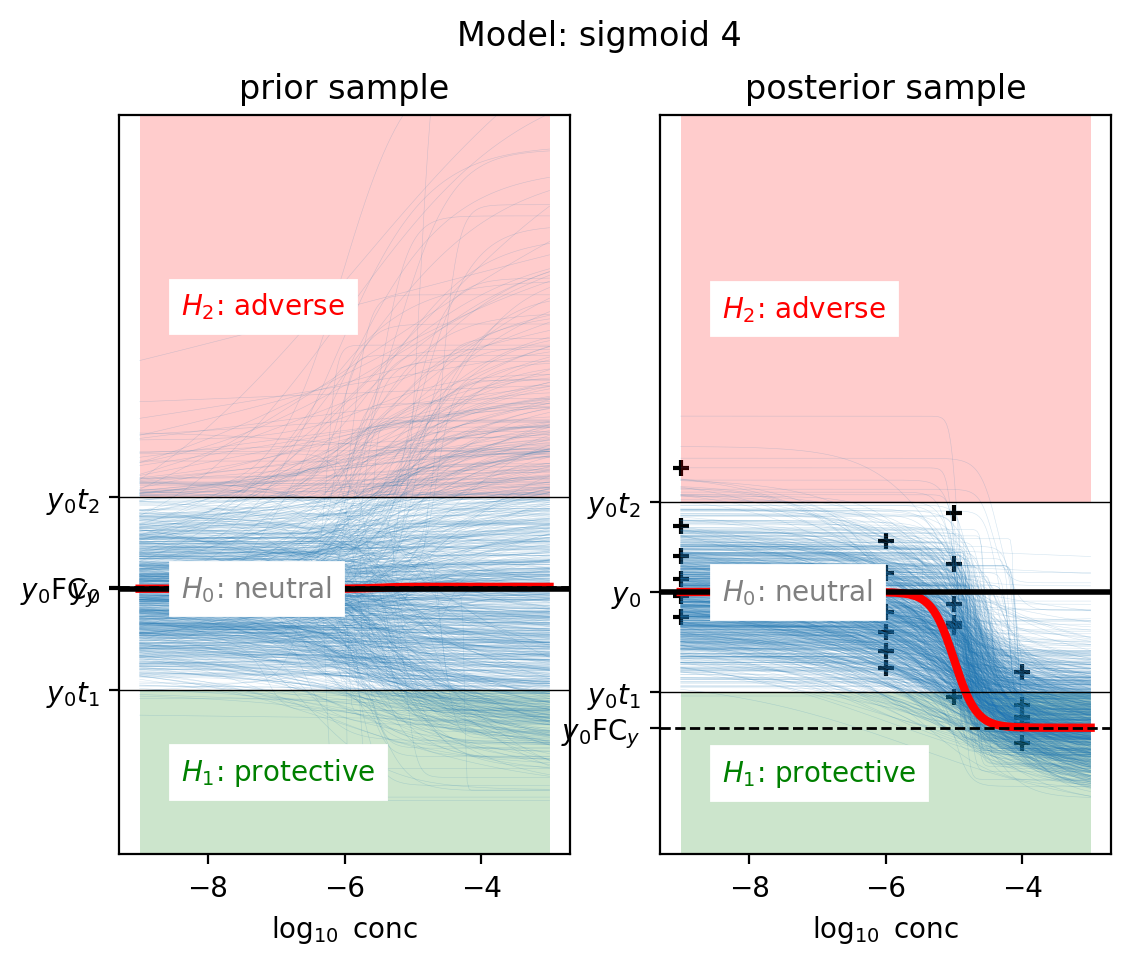

In [10]:
fig, ax = prior_posterior_curves(model_4, idata_4, data_reshaped)
fig.suptitle('Model: sigmoid 4')
fig.savefig(_fit_dir / 'prior-posterior-curves-sigmoid-4.png', bbox_inches='tight')
fig.savefig(_fit_dir / 'prior-posterior-curves-sigmoid-4.pdf', bbox_inches='tight')